# rbc_nob 확장성 — strong / weak scaling (1차: 2026-10-17, 1노드 np ≤ 4)

`apps/rbc_nob/scalability/out/scal_<mode>_<n>_np<N>/phase_timing_<hw>_<job>_r<rep>.csv` 를 읽는다
(`docs/Scalability/plan.md` §2 의 main 호출 단위 구간 타이머, 200 스텝 중 워밍업 50 제외, 반복 3회 중 `step_total` 중앙값 런).
순위·해석은 `docs/Scalability/ranking_20261017.md`.

| 모드 | 정의 | 효율 |
|---|---|---|
| strong | 전역 격자 고정 (256³, 512³), npz = np | $E = \dfrac{T(np_0)}{T(np)\,(np/np_0)}$ |
| weak | 랭크당 256³ 고정, 전역 nz = 256·np | $E = \dfrac{T(np_0)}{T(np)}$ |

T = step_total 의 랭크 max (ms/step). 색 = 하드웨어(H200 파랑, A100 주황, V100 청록), 선 모양 = 격자(256³ 실선 ○, 512³ 파선 □).
A100 8 GPU·다노드 결과(np 8·16·32)는 잡이 끝나면 같은 폴더에 쌓이고 이 노트북을 다시 실행하면 자동으로 들어온다.

In [ ]:
import csv, glob, os, re, statistics
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "scalability", "out"))   # apps/rbc_nob/scalability/out
SAVE_FIG = False                                                                      # plot/scalability_*.png (gitignore)

# 하드웨어 = 색 (dataviz 기준 팔레트 슬롯 1·2·3, 검증 통과), 격자 = 선 모양·마커
HW = {"h200": ("H200 143GB", "#2a78d6"), "a100": ("A100 80GB", "#eb6834"), "v100": ("V100 32GB", "#1baf7a")}
GRID = {256: ("-", "o"), 512: ("--", "s")}
PHASES = ["momentum_solve", "scalar_solve", "momentum_rhs", "pressure_solve", "pressure_rhs", "pressure_correct",
          "properties_1", "properties_2", "sync_T", "sync_UVW_1", "sync_UVW_2", "predictor", "dt_cfl", "dt_viscous", "clip", "monitor"]

def load_runs(out_dir=OUT_DIR, tags=None):
    """{(hw, mode, n, np): [ {phase: (min, avg, max, share, imbalance)} per repeat ]}
       tags=None → HW 의 꼬리표만 (scaling 그림), "all" → 모든 꼬리표 (momentum 세부 런 h200m 등 포함)"""
    runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(out_dir, "scal_*", "phase_timing_*.csv"))):
        m = re.search(r"scal_(strong|weak)_(\d+)_np(\d+)/phase_timing_([a-z0-9]+)_(\d+)_r(\d+)\.csv$", path)
        if not m:
            continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row[0] != "phase":
                    ph[row[0]] = tuple(float(x) for x in row[1:])
        if tags != "all" and m.group(4) not in HW:   # 알 수 없는 꼬리표(예: h200m = momentum 세부 측정)는 건너뛴다
            continue
        runs[(m.group(4), m.group(1), int(m.group(2)), int(m.group(3)))].append(ph)
    return runs

def median_run(reps):
    reps = sorted(reps, key=lambda r: r["step_total"][2])
    return reps[len(reps) // 2]

runs = load_runs()
cases = {k: median_run(v) for k, v in runs.items()}            # 대표 런
T = {k: v["step_total"][2] for k, v in cases.items()}          # ms/step (랭크 max)
print(f"{len(cases)} cases from {OUT_DIR}")
for k in sorted(cases):
    reps = [r["step_total"][2] for r in runs[k]]
    spread = (max(reps) - min(reps)) / statistics.median(reps) * 100
    print(f"  {k[0]:5s} {k[1]:6s} {k[2]}^3 np{k[3]:<3d} {T[k]:8.2f} ms/step  (x{len(reps)}, spread {spread:.1f}%)")

18 cases from /scratch/r908a06/KDH/MPM-STD_C/apps/rbc_nob/scalability/out
  a100  strong 256^3 np1      83.58 ms/step  (x3, spread 0.0%)
  a100  strong 512^3 np1     698.50 ms/step  (x3, spread 0.0%)
  a100  weak   256^3 np1      83.57 ms/step  (x3, spread 0.0%)
  h200  strong 256^3 np1      41.39 ms/step  (x5, spread 0.5%)
  h200  strong 256^3 np2      25.87 ms/step  (x3, spread 0.1%)
  h200  strong 256^3 np4      16.96 ms/step  (x3, spread 0.5%)
  h200  strong 512^3 np1     328.96 ms/step  (x3, spread 0.0%)
  h200  strong 512^3 np2     172.49 ms/step  (x3, spread 0.0%)
  h200  strong 512^3 np4      91.19 ms/step  (x3, spread 0.1%)
  h200  weak   256^3 np1      41.35 ms/step  (x3, spread 0.1%)
  h200  weak   256^3 np2      44.01 ms/step  (x3, spread 0.1%)
  h200  weak   256^3 np4      44.27 ms/step  (x3, spread 0.1%)
  v100  strong 256^3 np1     197.72 ms/step  (x3, spread 0.0%)
  v100  strong 256^3 np2      95.17 ms/step  (x3, spread 0.0%)
  v100  strong 256^3 np4      52.81 ms/step 

## 1. Strong scaling — 전역 격자 고정

왼쪽: 스텝당 시간(랭크 max) vs GPU 수, 회색 점선 = 이상적 1/np. 오른쪽: 병렬 효율.
기준 np₀ = 그 시리즈의 가장 작은 np (A100 512³ 은 np 1 이 80 GB 에 들어가 np 1 기준).

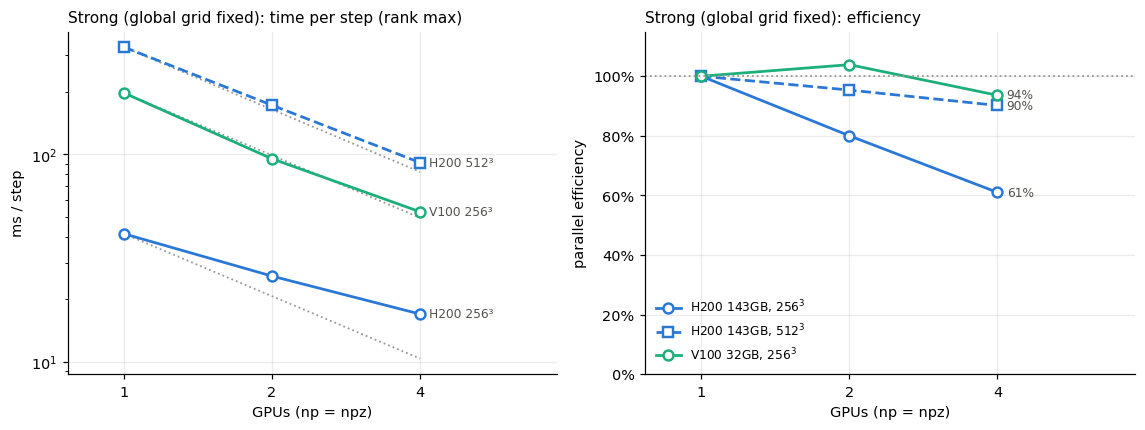

In [ ]:
def series(mode):
    """{(hw, n): array[[np, T], ...]} — np 오름차순, 점 2개 이상인 시리즈만"""
    out = defaultdict(list)
    for (hw, m, n, npz), t in T.items():
        if m == mode:
            out[(hw, n)].append((npz, t))
    return {k: np.array(sorted(v)) for k, v in out.items() if len(v) >= 2}

def style_np_axis(ax, nps):
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_locator(FixedLocator(sorted(nps)))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xticklabels([str(int(p)) for p in sorted(nps)])
    ax.set_xlabel("GPUs (np = npz)")

def plot_scaling(mode, efficiency, ideal, ylabel_time, title, fname):
    data = series(mode)
    if not data:
        print(f"no {mode} series with >= 2 points yet"); return
    nps = sorted({int(p) for arr in data.values() for p in arr[:, 0]})
    fig, (ax_t, ax_e) = plt.subplots(1, 2, figsize=(10.5, 4.0))
    for (hw, n), arr in sorted(data.items()):
        label, color = HW[hw]; ls, mk = GRID[n]
        x, y = arr[:, 0], arr[:, 1]
        ax_t.plot(x, y, ls, marker=mk, color=color, lw=1.8, ms=6.5, mfc="white", mew=1.6, label=f"{label}, {n}$^3$")
        ax_t.plot(x, ideal(x, y), ":", color="#9a9a96", lw=1.2, zorder=1)
        ax_t.annotate(f"{hw.upper()} {n}³", (x[-1], y[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
        e = efficiency(x, y)
        ax_e.plot(x, e, ls, marker=mk, color=color, lw=1.8, ms=6.5, mfc="white", mew=1.6, label=f"{label}, {n}$^3$")
        ax_e.annotate(f"{100*e[-1]:.0f}%", (x[-1], e[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
    ax_t.set_yscale("log"); ax_t.set_ylabel(ylabel_time); ax_t.set_title(f"{title}: time per step (rank max)", fontsize=10, loc="left")
    ax_e.axhline(1.0, color="#9a9a96", ls=":", lw=1.2); ax_e.set_ylim(0, 1.15)
    ax_e.yaxis.set_major_formatter(PercentFormatter(1.0)); ax_e.set_ylabel("parallel efficiency"); ax_e.set_title(f"{title}: efficiency", fontsize=10, loc="left")
    for ax in (ax_t, ax_e):
        style_np_axis(ax, nps); ax.set_xlim(min(nps) / 1.3, max(nps) * 1.9)
    ax_e.legend(frameon=False, loc="lower left", ncol=1)
    fig.tight_layout()
    if SAVE_FIG:
        fig.savefig(fname, bbox_inches="tight")
    return fig

plot_scaling("strong",
             efficiency=lambda x, y: (y[0] / y) / (x / x[0]),
             ideal=lambda x, y: y[0] * x[0] / x,
             ylabel_time="ms / step", title="Strong (global grid fixed)", fname="scalability_strong.png");

## 2. Weak scaling — 랭크당 256³ 고정

전역 격자 = 256 × 256 × 256·np, lz = np. 랭크당 일이 같으므로 이상적이면 시간이 평평하다(회색 점선).
늘어나는 양 = z 분산 TDMA 의 축소계 통신(np 에 비례) + halo 비용 변화.

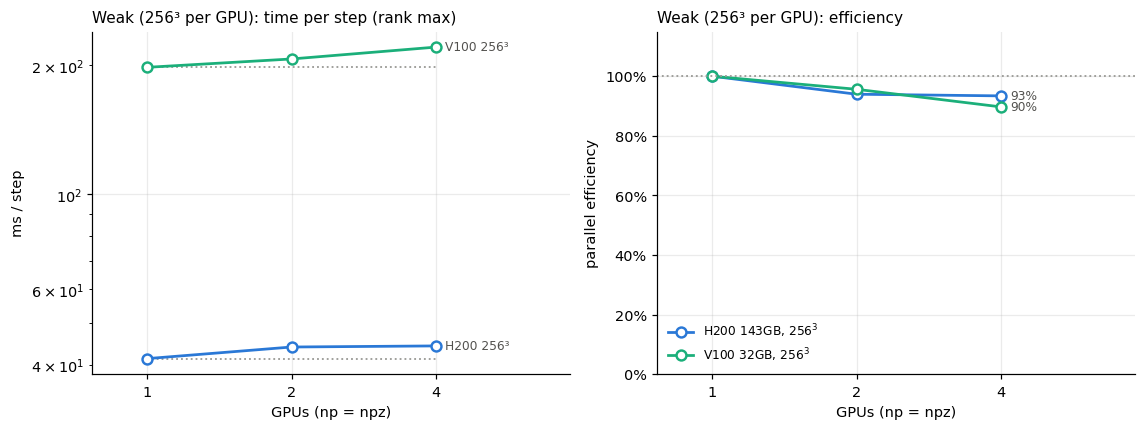

In [ ]:
plot_scaling("weak",
             efficiency=lambda x, y: y[0] / y,
             ideal=lambda x, y: np.full_like(y, y[0]),
             ylabel_time="ms / step", title="Weak (256³ per GPU)", fname="scalability_weak.png");

## 3. 스텝 구성 — 구간별 ms/step (누적 막대) 와 확장 손실

구간을 7 묶음으로: ADI 풀이 3개(momentum / scalar / pressure), 로컬 커널(rhs·보정·물성·클립), halo 동기화(sync_T·sync_UVW×2·predictor),
dt(리덕션+Allreduce), monitor. 분산 TDMA 의 MPI 시간(`tdma_comm_*_z`, 풀이 안에 포함)은 막대 위 검은 눈금으로 따로 표시.
오른쪽: 가장 큰 np 에서의 확장 손실 $\;\mathrm{loss}_p = T_p(np) - T_p(np_0)/(np/np_0)$ (strong) — plan.md §5 의 순위 기준.

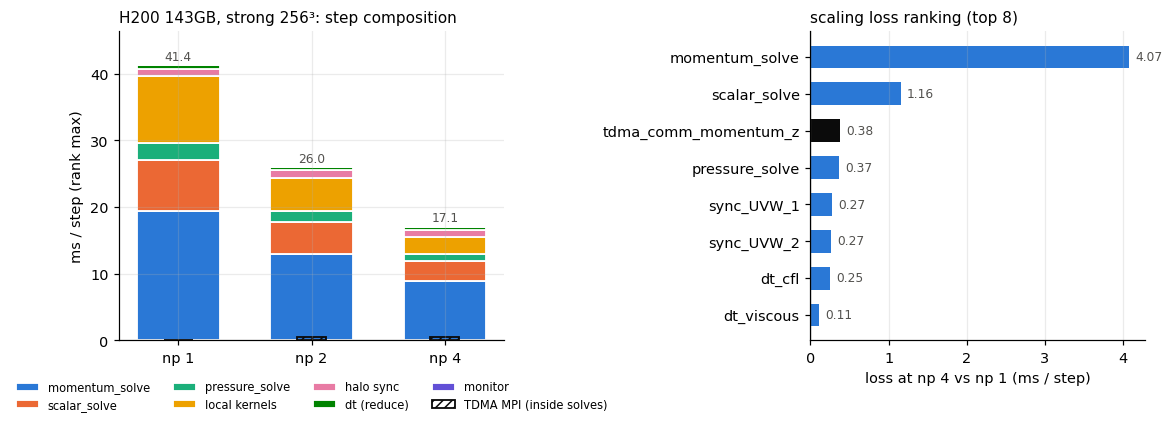

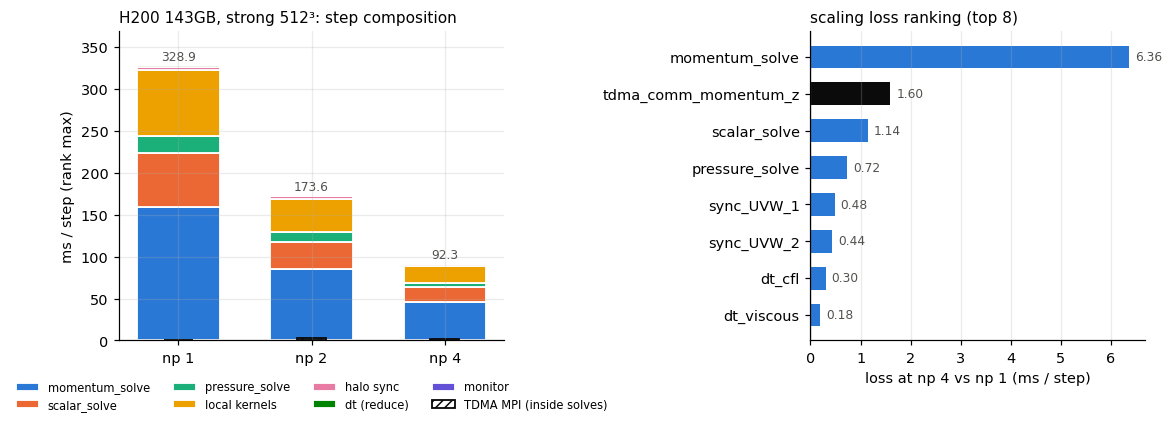

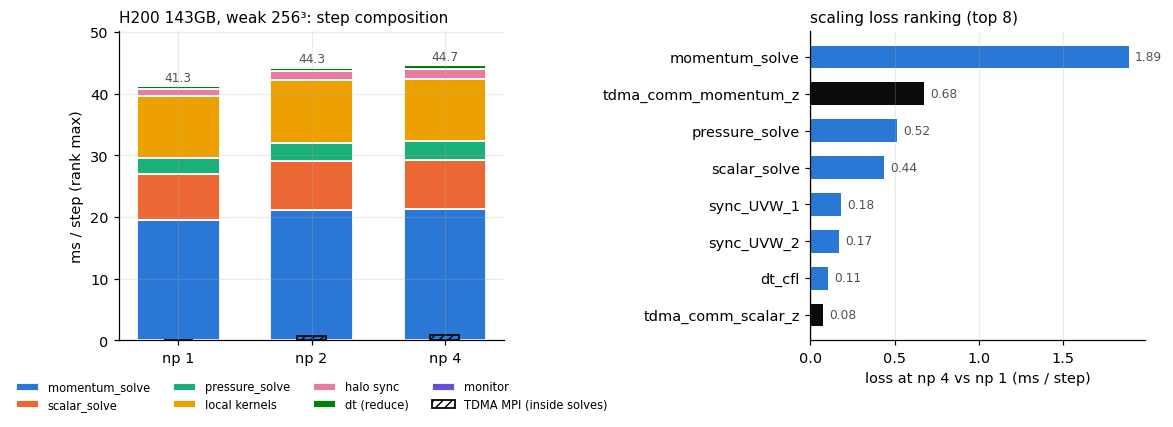

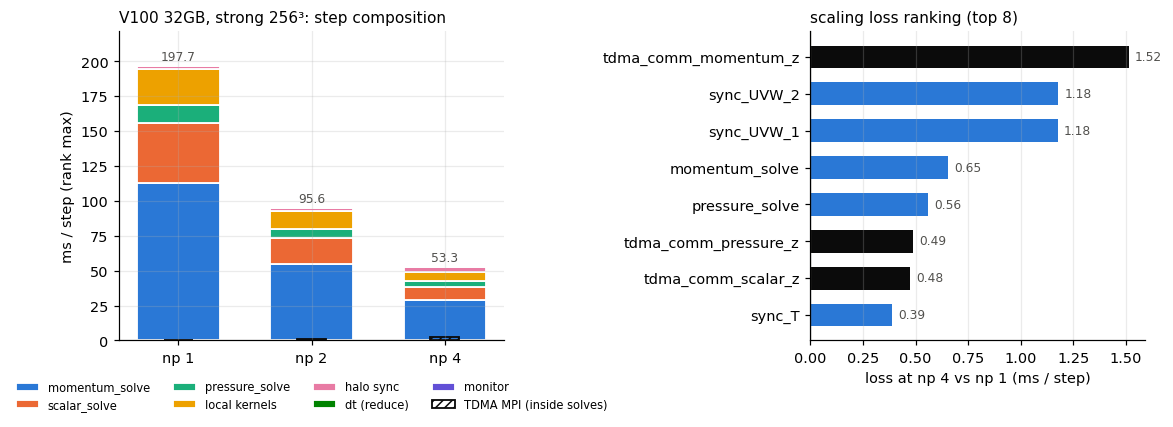

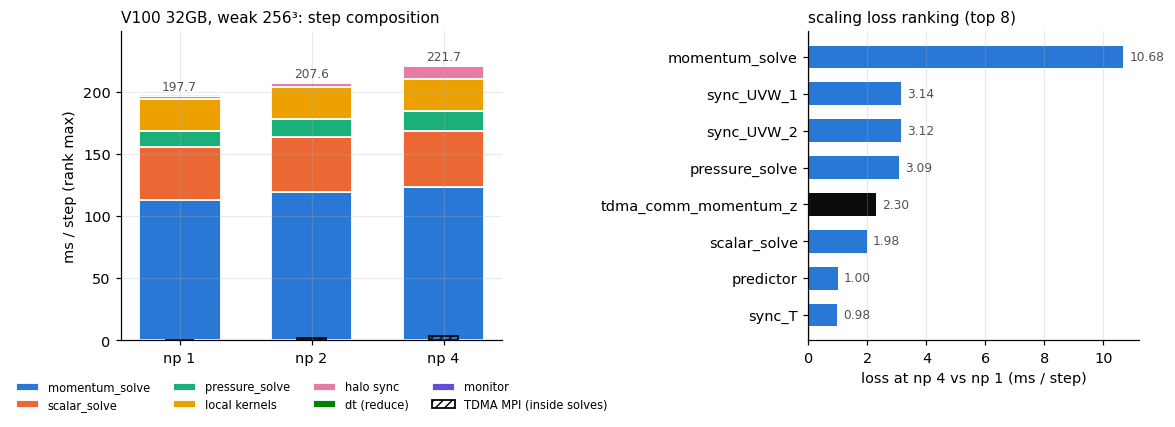

In [ ]:
GROUPS = [("momentum_solve", ["momentum_solve"]), ("scalar_solve", ["scalar_solve"]), ("pressure_solve", ["pressure_solve"]),
          ("local kernels", ["momentum_rhs", "pressure_rhs", "pressure_correct", "properties_1", "properties_2", "clip"]),
          ("halo sync", ["sync_T", "sync_UVW_1", "sync_UVW_2", "predictor"]), ("dt (reduce)", ["dt_cfl", "dt_viscous"]), ("monitor", ["monitor"])]
GROUP_COLOR = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]   # 팔레트 슬롯 1–7, 고정 순서
TDMA = ["tdma_comm_scalar_z", "tdma_comm_momentum_z", "tdma_comm_pressure_z"]

def grouped(ph):
    return {g: sum(ph[p][2] for p in members if p in ph) for g, members in GROUPS}

def plot_breakdown(mode, hw, n):
    keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
    if len(keys) < 2:
        return
    fig, (ax_b, ax_l) = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1.15, 1]})
    xs = np.arange(len(keys)); width = 0.62
    bottoms = np.zeros(len(keys))
    for (g, _), color in zip(GROUPS, GROUP_COLOR):
        vals = np.array([grouped(cases[k])[g] for k in keys])
        ax_b.bar(xs, vals, width, bottom=bottoms, color=color, edgecolor="white", linewidth=1.2, label=g)
        bottoms += vals
    tdma = np.array([sum(cases[k][p][2] for p in TDMA if p in cases[k]) for k in keys])
    ax_b.bar(xs, tdma, width * 0.35, bottom=0, color="none", edgecolor="#0b0b0b", linewidth=1.2, hatch="////", label="TDMA MPI (inside solves)")
    for x, k, tot in zip(xs, keys, bottoms):
        ax_b.annotate(f"{tot:.1f}", (x, tot), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color="#52514e")
    ax_b.set_xticks(xs); ax_b.set_xticklabels([f"np {k[3]}" for k in keys]); ax_b.set_ylabel("ms / step (rank max)")
    ax_b.set_title(f"{HW[hw][0]}, {mode} {n}³: step composition", fontsize=10, loc="left")
    ax_b.set_ylim(0, bottoms.max() * 1.12)
    ax_b.legend(frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
    # 손실 순위 (가장 큰 np, 16 구간 + TDMA MPI 3개)
    k0, kN = keys[0], keys[-1]; ratio = kN[3] / k0[3]
    rows = []
    for p in PHASES + TDMA:
        if p not in cases[kN] or p not in cases[k0]:
            continue
        tp, t0 = cases[kN][p][2], cases[k0][p][2]
        rows.append((tp - (t0 / ratio if mode == "strong" else t0), p))
    rows.sort()
    top = rows[-8:]
    ax_l.barh([p for _, p in top], [v for v, _ in top], color=["#2a78d6" if not p.startswith("tdma") else "#0b0b0b" for _, p in top], height=0.62)
    for v, p in top:
        ax_l.annotate(f"{v:.2f}", (v, p), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
    ax_l.axvline(0, color="#52514e", lw=0.8)
    ax_l.set_xlabel(f"loss at np {kN[3]} vs np {k0[3]} (ms / step)"); ax_l.set_title("scaling loss ranking (top 8)", fontsize=10, loc="left")
    ax_l.grid(axis="y", visible=False)
    fig.tight_layout()
    if SAVE_FIG:
        fig.savefig(f"scalability_breakdown_{mode}_{hw}_{n}.png", bbox_inches="tight")
    return fig

for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_breakdown(mode, hw, n)
plt.show()

## 5. momentum_solve 내부 — 호출별 분해

`momentum::solve_variable_property` 가 부르는 모든 호출을 따로 잰 런(꼬리표 `h200m`·`v100m`, 그리고 새 바이너리로 돈 A100 잡).
구간 이름 `momentum.<dU|dV|dW>.<build_x|tdma_x|scatter_x|…|halo|wall_ghost|couple_rhs>` + `momentum.post.*` (사후 커플링·증분 적용).
막대는 세 성분을 합쳐 호출 종류 8 묶음으로 쌓고(색 고정 순서), 오른쪽은 가장 큰 np 에서의 손실 순위(momentum 잎 구간만).
아래 표는 np 1 의 성분 × 호출 ms/step — **어느 커널이 큰지**는 여기서 바로 보인다.

15 cases with momentum breakdown: ['h200m', 'v100m']


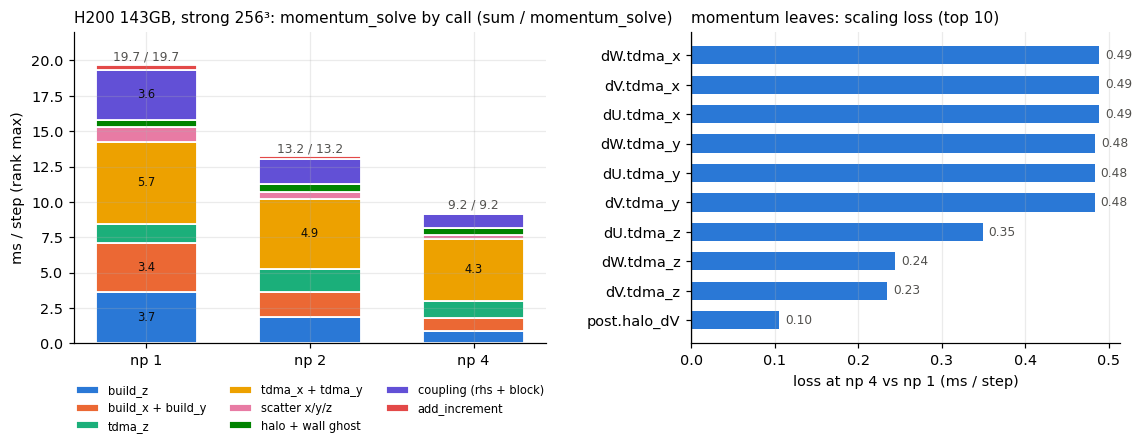

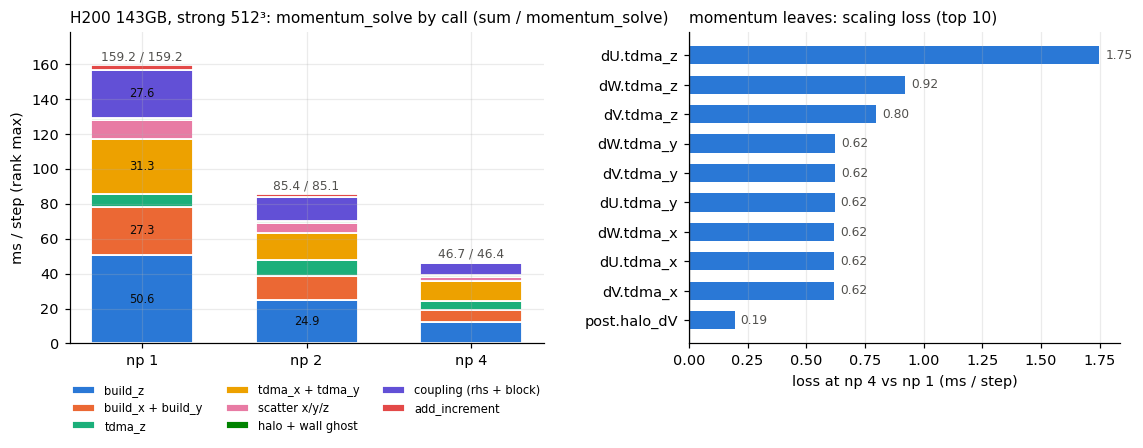

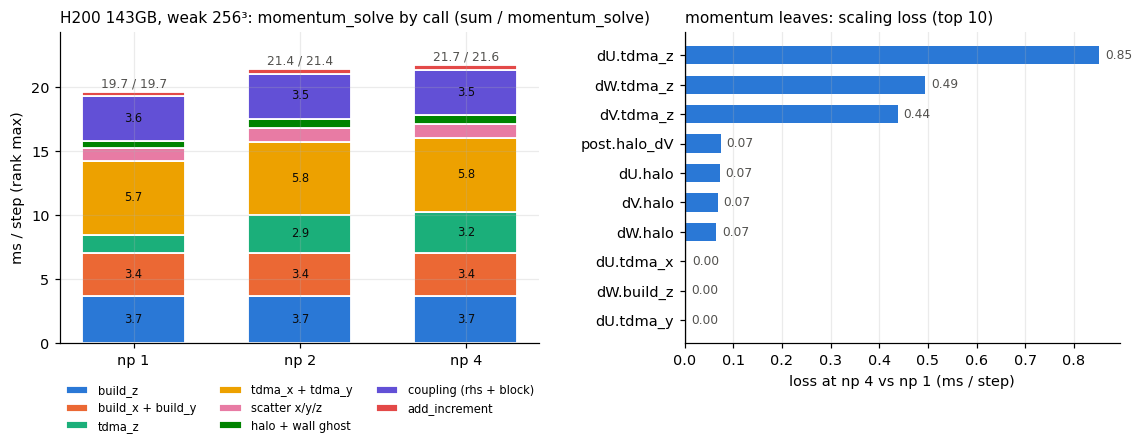

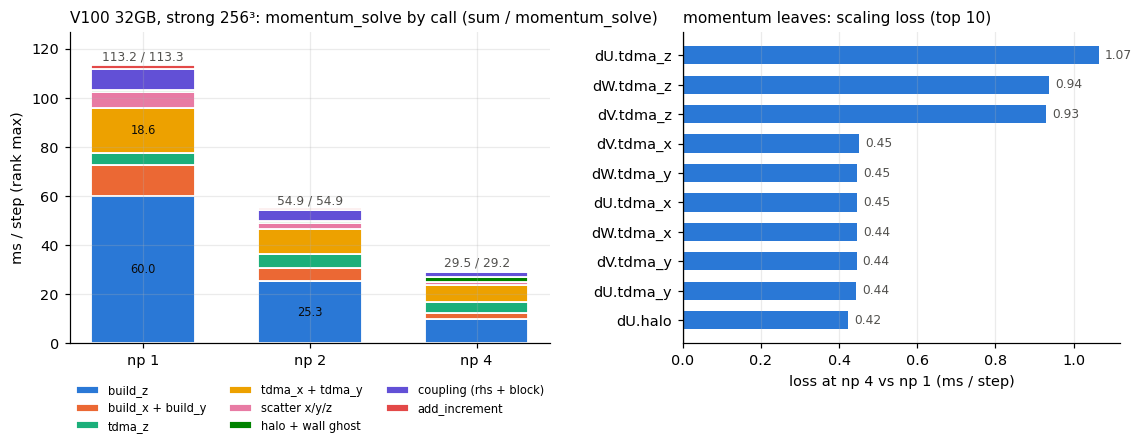

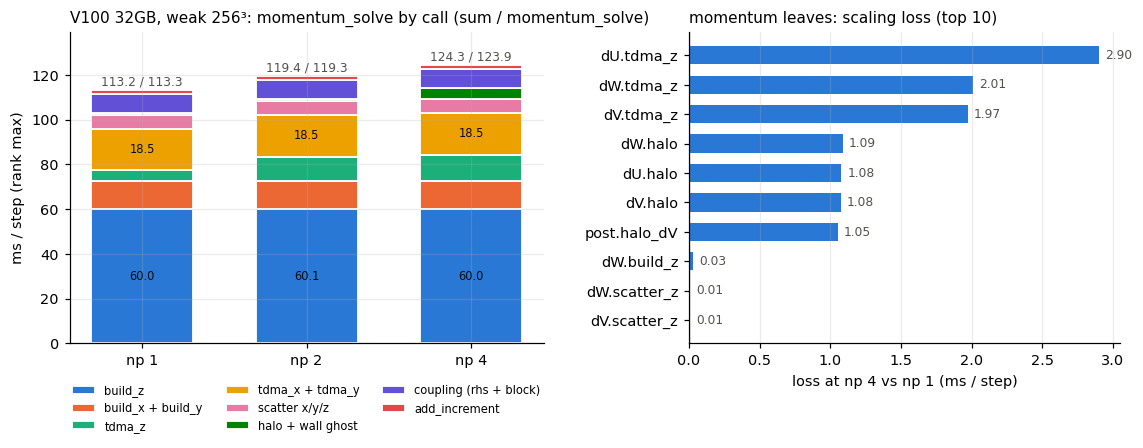

In [ ]:
all_runs = load_runs(tags="all")
mcases = {k: median_run(v) for k, v in all_runs.items() if any(n.startswith("momentum.") for n in v[0])}
print(f"{len(mcases)} cases with momentum breakdown:", sorted({k[0] for k in mcases}))

MOM_KIND = [("build_z", lambda n: n.endswith(".build_z")),
            ("build_x + build_y", lambda n: n.endswith(".build_x") or n.endswith(".build_y")),
            ("tdma_z", lambda n: n.endswith(".tdma_z")),
            ("tdma_x + tdma_y", lambda n: n.endswith(".tdma_x") or n.endswith(".tdma_y")),
            ("scatter x/y/z", lambda n: ".scatter_" in n),
            ("halo + wall ghost", lambda n: ".halo" in n or "wall_ghost" in n),
            ("coupling (rhs + block)", lambda n: "couple" in n),
            ("add_increment", lambda n: n.endswith("add_increment"))]
KIND_COLOR = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

def mom_leaves(ph):
    return {n: v for n, v in ph.items() if n.startswith("momentum.")}

def hw_label(tag):
    return HW.get(tag.rstrip("m"), (tag, "#52514e"))[0]

def plot_momentum(mode, tag, n):
    keys = sorted(k for k in mcases if k[:3] == (tag, mode, n))
    if not keys:
        return
    fig, (ax_b, ax_l) = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
    xs = np.arange(len(keys)); width = 0.62; bottoms = np.zeros(len(keys))
    for (kind, pred), color in zip(MOM_KIND, KIND_COLOR):
        vals = np.array([sum(v[2] for nm, v in mom_leaves(mcases[k]).items() if pred(nm)) for k in keys])
        ax_b.bar(xs, vals, width, bottom=bottoms, color=color, edgecolor="white", linewidth=1.2, label=kind)
        for x, b, v in zip(xs, bottoms, vals):            # 큰 조각은 값 직접 표기 (relief)
            if v > 0.12 * max(1e-9, sum(v2[2] for v2 in mom_leaves(mcases[keys[0]]).values())):
                ax_b.annotate(f"{v:.1f}", (x, b + v / 2), ha="center", va="center", fontsize=7.5, color="#0b0b0b")
        bottoms += vals
    for x, k, tot in zip(xs, keys, bottoms):
        ax_b.annotate(f"{tot:.1f} / {mcases[k]['momentum_solve'][2]:.1f}", (x, tot), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color="#52514e")
    ax_b.set_ylim(0, bottoms.max() * 1.12)
    ax_b.set_xticks(xs); ax_b.set_xticklabels([f"np {k[3]}" for k in keys]); ax_b.set_ylabel("ms / step (rank max)")
    ax_b.set_title(f"{hw_label(tag)}, {mode} {n}³: momentum_solve by call (sum / momentum_solve)", fontsize=10, loc="left")
    ax_b.legend(frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
    # 손실 순위: momentum 잎 구간, 가장 큰 np
    k0, kN = keys[0], keys[-1]; ratio = kN[3] / k0[3]
    rows = []
    for nm, v in mom_leaves(mcases[kN]).items():
        if nm in mcases[k0]:
            t0 = mcases[k0][nm][2]
            rows.append((v[2] - (t0 / ratio if mode == "strong" else t0), nm.replace("momentum.", "")))
    rows.sort(); top = rows[-10:]
    ax_l.barh([p for _, p in top], [v for v, _ in top], color="#2a78d6", height=0.62)
    for v, p in top:
        ax_l.annotate(f"{v:.2f}", (v, p), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
    ax_l.axvline(0, color="#52514e", lw=0.8); ax_l.grid(axis="y", visible=False)
    ax_l.set_xlabel(f"loss at np {kN[3]} vs np {k0[3]} (ms / step)"); ax_l.set_title("momentum leaves: scaling loss (top 10)", fontsize=10, loc="left")
    fig.tight_layout()
    if SAVE_FIG:
        fig.savefig(f"scalability_momentum_{mode}_{tag}_{n}.png", bbox_inches="tight")
    return fig

for tag in sorted({k[0] for k in mcases}):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_momentum(mode, tag, n)
plt.show()

In [ ]:
# np 1 의 성분 × 호출 표 (ms/step) — 하드웨어별
CALLS = ["build_x", "tdma_x", "scatter_x", "build_y", "tdma_y", "scatter_y", "build_z", "tdma_z", "scatter_z", "halo", "wall_ghost", "couple_rhs"]
for tag in sorted({k[0] for k in mcases}):
    for n in (256, 512):
        k = (tag, "strong", n, 1)
        if k not in mcases:
            continue
        ph = mcases[k]
        print(f"[{hw_label(tag)}] strong {n}^3 np 1 — momentum_solve {ph['momentum_solve'][2]:.1f} ms/step (step_total {ph['step_total'][2]:.1f})")
        print(f"  {'call':12s}" + "".join(f"{c:>9s}" for c in ("dU", "dV", "dW", "sum")))
        for c in CALLS:
            vals = [ph.get(f"momentum.{comp}.{c}", (0, 0, 0))[2] for comp in ("dU", "dV", "dW")]
            print(f"  {c:12s}" + "".join(f"{v:9.2f}" for v in vals) + f"{sum(vals):9.2f}")
        post = {nm.replace("momentum.post.", ""): v[2] for nm, v in ph.items() if nm.startswith("momentum.post.")}
        print("  post:        " + ", ".join(f"{a} {b:.2f}" for a, b in post.items()))
        rhs = {nm.replace("momentum_rhs.", ""): v[2] for nm, v in ph.items() if nm.startswith("momentum_rhs.")}
        print("  momentum_rhs:" + ", ".join(f" {a} {b:.2f}" for a, b in rhs.items()))
        print()

[H200 143GB] strong 256^3 np 1 — momentum_solve 19.7 ms/step (step_total 41.7)
  call               dU       dV       dW      sum
  build_x          0.48     0.61     0.60     1.70
  tdma_x           0.96     0.96     0.96     2.87
  scatter_x        0.10     0.10     0.10     0.31
  build_y          0.62     0.50     0.61     1.72
  tdma_y           0.96     0.96     0.96     2.87
  scatter_y        0.11     0.10     0.10     0.31
  build_z          1.69     1.05     0.94     3.67
  tdma_z           0.46     0.46     0.46     1.38
  scatter_z        0.15     0.15     0.15     0.45
  halo             0.11     0.11     0.11     0.33
  wall_ghost       0.01     0.01     0.01     0.03
  couple_rhs       0.00     0.65     1.21     1.85
  post:        block_couple_v 0.59, halo_dV 0.11, wall_ghost_dV 0.01, block_couple_u 1.11, add_increment 0.34
  momentum_rhs: fill 0.13,  advection_diffusion_u 2.08,  advection_diffusion_v 2.10,  advection_diffusion_w 2.32,  buoyancy 0.27,  pressure_gradient

## 4. 요약표 — np 1 의 구성과 np 별 효율

노트북 실행 시점의 데이터로 다시 계산된다. 구간 점유율은 `step_total` 대비.

In [ ]:
print("np 1 composition (share of step_total):")
hdr = [k for k in sorted(cases) if k[3] == 1 and k[1] == "strong"]
print(f"{'phase':18s}" + "".join(f"{k[0]} {k[2]}^3".rjust(14) for k in hdr))
for g, _ in GROUPS:
    print(f"{g:18s}" + "".join(f"{100*grouped(cases[k])[g]/T[k]:13.1f}%" for k in hdr))
print(f"{'step_total [ms]':18s}" + "".join(f"{T[k]:14.2f}" for k in hdr))
print()
for mode in ("strong", "weak"):
    for (hw, n), arr in sorted(series(mode).items()):
        x, y = arr[:, 0], arr[:, 1]
        e = (y[0] / y) / (x / x[0]) if mode == "strong" else y[0] / y
        print(f"{mode:6s} {hw:5s} {n}^3: " + "  ".join(f"np{int(p)} {100*v:.0f}%" for p, v in zip(x, e)))

np 1 composition (share of step_total):
phase                 a100 256^3    a100 512^3    h200 256^3    h200 512^3    v100 256^3
momentum_solve             49.0%         51.2%         47.1%         48.3%         57.1%
scalar_solve               21.1%         20.9%         18.2%         19.7%         21.6%
pressure_solve              6.1%          6.4%          6.2%          5.9%          6.5%
local kernels              21.2%         20.1%         24.4%         24.0%         13.1%
halo sync                   1.6%          0.7%          2.7%          1.1%          1.2%
dt (reduce)                 0.9%          0.6%          1.3%          0.8%          0.5%
monitor                     0.1%          0.0%          0.1%          0.1%          0.0%
step_total [ms]            83.58        698.50         41.39        328.96        197.72

strong h200  256^3: np1 100%  np2 80%  np4 61%
strong h200  512^3: np1 100%  np2 95%  np4 90%
strong v100  256^3: np1 100%  np2 104%  np4 94%
weak   h200  256